# 추론·상관·회귀·샘플링·스케일링 보충 정답지

추론통계·상관·회귀·샘플링·스케일링을 다루는 보충 단원입니다. 가상 예제의 결론을 실제 사람·서비스에 일반화하지 마세요.

**학습 목표:** 신뢰구간과 검정, 두 집단 비교와 효과 크기, 상관과 회귀, 샘플링과 편향, 스케일링과 데이터 누출

공식 → 직접 구현 또는 계산 → 라이브러리 대조 → 해석 순서로 학습합니다.

## 실행 준비

Python 3.11 이상, NumPy·pandas·SciPy·Matplotlib이 필요합니다. 없는 경우 별도 셀에서 `%pip install numpy pandas scipy matplotlib`을 한 번 실행하세요. 새 커널에서 위에서 아래로 실행합니다. 외부 데이터 다운로드는 없습니다. 그래프는 폰트 호환을 위해 영문 제목을 쓰고 해석은 한국어로 제공합니다.

**표기:** 기본 기술 분산은 ddof=0, 모집단 분산 추정·평균 추론은 ddof=1을 명시합니다. 난수는 seed=42(문제에 지정 시 해당 seed)입니다.

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
# 외부 파일 없이 재현 가능한 학습용 가상 자료
x = np.array([12, 15, 14, 10, 18, 20, 22, 25, 30, 28], dtype=float)
y = np.array([2, 4, 6, 8, 10, 12, 14, 40], dtype=float)
plt.rcParams['axes.unicode_minus'] = False


## 문제 1. 신뢰구간과 검정

x의 평균 95% 신뢰구간과 H0:μ=20인 양측 단일표본 t검정을 구하세요. alpha=.05로 판단하고 가정을 적으세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [2]:
# 문제 1 풀이
se=x.std(ddof=1)/np.sqrt(len(x));ci=stats.t.interval(.95,df=len(x)-1,loc=x.mean(),scale=se)
r=stats.ttest_1samp(x,20)
print(ci,r,'기각' if r.pvalue<.05 else '기각하지 못함')

(np.float64(14.522499109611157), np.float64(24.27750089038884)) TtestResult(statistic=np.float64(-0.27827658634639846), pvalue=np.float64(0.787087624802837), df=np.int64(9)) 기각하지 못함


**결과 해석 / 근거 / 새로 알게 된 점:**

구간은 20을 포함하며 .05에서 기각할 근거가 부족합니다. 이는 μ=20의 입증이 아닙니다. 작은 독립 표본의 정규성·이상치와 표집 방법을 확인합니다. 표준편차와 표준오차를 혼동하지 않습니다.

## 문제 2. 두 집단 비교와 효과 크기

before=[70,72,68,75,71,69], after=[73,74,72,76,75,72]의 전후 평균차와 양측 대응 t검정을 구하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [3]:
# 문제 2 풀이
before=np.array([70,72,68,75,71,69]);after=np.array([73,74,72,76,75,72])
d=after-before
print('평균차',d.mean(),stats.ttest_rel(after,before))
assert np.isclose(d.mean(),17/6)

평균차 2.8333333333333335 TtestResult(statistic=np.float64(5.936657514041416), pvalue=np.float64(0.001935836403248031), df=np.int64(5))


**결과 해석 / 근거 / 새로 알게 된 점:**

차이는 약 2.833점입니다. 같은 사람의 차이들이 독립이고 차이의 정규성 가정이 적절해야 합니다. 통계적으로 유의해도 교육 효과의 실무적 크기와 무작위 배정 여부를 별도로 판단합니다.

## 문제 3. 상관과 회귀

공부시간 [1,2,3,4,5,6]과 점수 [50,55,65,64,75,80]의 Pearson r, 회귀식, 4시간 예측을 구하고 인과·외삽 위험을 적으세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

0.9791796344589871 43.93333333333332 5.971428571428572 4시간 예측 67.81904761904761


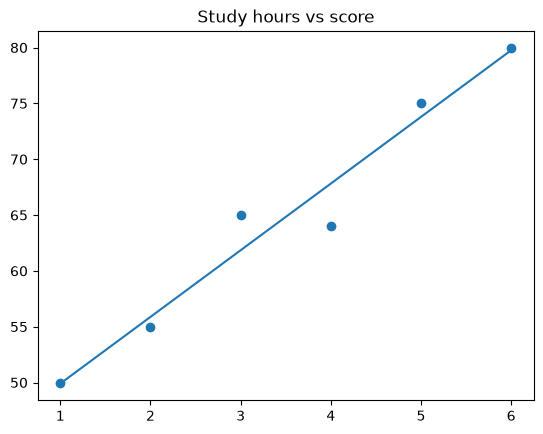

In [4]:
# 문제 3 풀이
hours=np.arange(1,7);score=np.array([50,55,65,64,75,80])
r=stats.linregress(hours,score)
print(r.rvalue,r.intercept,r.slope,'4시간 예측',r.intercept+r.slope*4)
plt.scatter(hours,score);plt.plot(hours,r.intercept+r.slope*hours);plt.title('Study hours vs score');plt.show()

**결과 해석 / 근거 / 새로 알게 된 점:**

양의 선형 관계를 보입니다. 다른 학습 배경 등의 교란이 있어 상관만으로 인과를 주장할 수 없습니다. 관측 범위를 벗어난 장시간 예측은 직선 관계를 보장하지 않습니다.

## 문제 4. 샘플링과 편향

A 60명, B 40명 모집단에서 10명을 비례 층화 비복원 추출하세요(seed=42). id 중복 여부와 집단 수를 확인하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [5]:
# 문제 4 풀이
pop=pd.DataFrame({'id':range(100),'group':['A']*60+['B']*40})
s=pd.concat([pop[pop.group=='A'].sample(n=6,random_state=42),pop[pop.group=='B'].sample(n=4,random_state=42)])
print(s,s.group.value_counts());assert len(s)==10 and s.id.is_unique

    id group
0    0     A
5    5     A
36  36     A
45  45     A
13  13     A
54  54     A
79  79     B
76  76     B
75  75     B
86  86     B group
A    6
B    4
Name: count, dtype: int64


**결과 해석 / 근거 / 새로 알게 된 점:**

A 6명, B 4명으로 모집단 비율을 보존합니다. 각 층 안에서도 무작위 추출이 필요합니다. 이 설계는 집단 누락을 줄이지만 모집단 명부의 누락 편향은 해결하지 못합니다.

## 문제 5. 스케일링과 데이터 누출

train=[2,4,6,8], test=[10,12]를 학습 통계만 써서 Z표준화(ddof=0)와 Min-Max 변환하세요. 상수 자료 처리도 설명하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [6]:
# 문제 5 풀이
train=np.array([2,4,6,8.]);test=np.array([10,12.])
mu,sd=train.mean(),train.std(ddof=0);lo,span=train.min(),np.ptp(train)
print('Z train/test',(train-mu)/sd,(test-mu)/sd)
print('MinMax train/test',(train-lo)/span,(test-lo)/span)
assert np.allclose((test-lo)/span,[4/3,5/3])

Z train/test [-1.34164079 -0.4472136   0.4472136   1.34164079] [2.23606798 3.13049517]
MinMax train/test [0.         0.33333333 0.66666667 1.        ] [1.33333333 1.66666667]


**결과 해석 / 근거 / 새로 알게 된 점:**

Min-Max 테스트 결과는 약 1.333과 1.667입니다. test를 이용해 범위를 다시 맞추면 누출이 생깁니다. 상수 열은 분모 0이므로 제거하거나 명시된 정책으로 0을 부여하는 등 별도 처리합니다.

## 복습 순서

1. 관측 대상과 통계량의 의미를 말로 설명합니다.
2. 분모·단위·독립성·분포 가정을 확인합니다.
3. 직접 계산과 라이브러리 결과를 비교합니다.
4. 코드 결과와 실제로 주장할 수 있는 범위를 구분합니다.

**학습 이동:** `Statistics_4_inference_extension.ipynb` → `Statistics_4_inference_extension_Practice.ipynb` → `Statistics_4_inference_extension_Answer.ipynb`.